In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# to Make the output easier to read
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

Loading the dataset.

In [2]:
df=pd.read_csv('insurance.csv')

Checking the first 5 rows of the dataset

In [3]:
print(df.head())

   age     sex   bmi  children smoker     region   charges
0   19  female 27.90         0    yes  southwest 16,884.92
1   18    male 33.77         1     no  southeast  1,725.55
2   28    male 33.00         3     no  southeast  4,449.46
3   33    male 22.70         0     no  northwest 21,984.47
4   32    male 28.88         0     no  northwest  3,866.86


In [4]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

Rows: 1338, Columns: 7


Overview of the data type and non-null counts

In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


Checking for null values

In [6]:
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Checking for duplicates

In [7]:
print(df.duplicated().sum())

1


In [8]:
print(df[df.duplicated(keep = False)])

     age   sex   bmi  children smoker     region  charges
195   19  male 30.59         0     no  northwest 1,639.56
581   19  male 30.59         0     no  northwest 1,639.56


In [9]:
df=df.drop_duplicates().reset_index(drop=True)

In [10]:
print(df)

      age     sex   bmi  children smoker     region   charges
0      19  female 27.90         0    yes  southwest 16,884.92
1      18    male 33.77         1     no  southeast  1,725.55
2      28    male 33.00         3     no  southeast  4,449.46
3      33    male 22.70         0     no  northwest 21,984.47
4      32    male 28.88         0     no  northwest  3,866.86
...   ...     ...   ...       ...    ...        ...       ...
1332   50    male 30.97         3     no  northwest 10,600.55
1333   18  female 31.92         0     no  northeast  2,205.98
1334   18  female 36.85         0     no  southeast  1,629.83
1335   21  female 25.80         0     no  southwest  2,007.94
1336   61  female 29.07         0    yes  northwest 29,141.36

[1337 rows x 7 columns]


We found one duplicate in the dataset and it had to be dropped 
as it can cause problems in our future analysis and building our model.

UNIVARIATE ANALYSIS

Age distribution analysis (Univariate) using histogram.

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

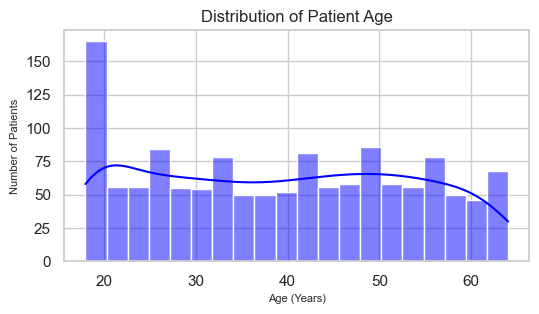

In [12]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 3))
sns.histplot(df['age'], kde=True, bins=20, color='blue')
plt.title('Distribution of Patient Age', fontsize=12)
plt.xlabel('Age (Years)', fontsize=8)
plt.ylabel('Number of Patients', fontsize=8)
plt.show()

Key Finding (Age Distribution):
Patient's ages range from 18 to 64 years old.
The distribution is relatively uniform across middle-aged groups, with a significant spike in young adults (ages 18–20).
Policyholders aged 60 and above represent the smallest proportion of customers in this dataset.

Sex Distribution Analysis using countplot.(Univariate)

<function matplotlib.pyplot.show(close=None, block=None)>

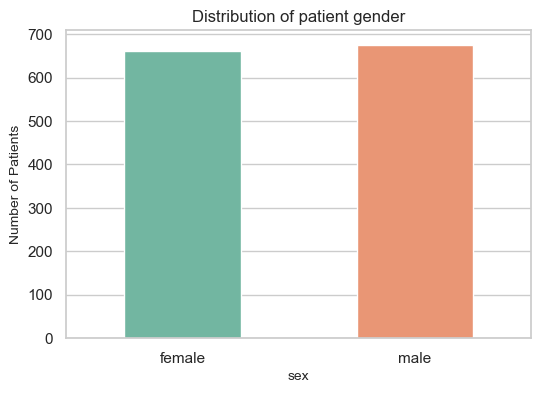

In [13]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='sex',hue='sex', palette='Set2', legend=False,width=0.5)
plt.title('Distribution of patient gender', fontsize=12)
plt.xlabel('sex',fontsize= 10)
plt.ylabel('Number of Patients',fontsize= 10)
plt.show


Key Finding (Sex Distribution):
The dataset is nearly evenly split between genders: 675 males (~50.5%) and 662 females (~49.5%).
Because neither gender dominates the sample, gender-based bias is minimal in the baseline dataset.

BMI distribution analysis using histogram(Univariate)

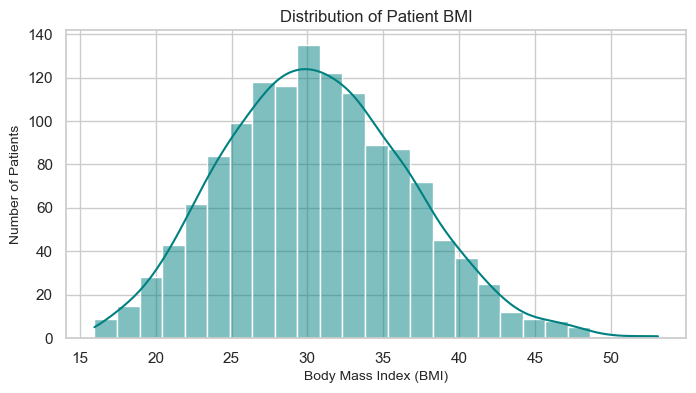

BMI SUMMARY STATISTICS
Mean BMI:   30.66
Median BMI: 30.40
Min BMI:    15.96
Max BMI:    53.13


In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(df['bmi'], kde=True, bins=25, color='teal')
plt.title('Distribution of Patient BMI', fontsize=12)
plt.xlabel('Body Mass Index (BMI)', fontsize=10)
plt.ylabel('Number of Patients', fontsize=10)
plt.show()

print("BMI SUMMARY STATISTICS")
print(f"Mean BMI:   {df['bmi'].mean():.2f}")
print(f"Median BMI: {df['bmi'].median():.2f}")
print(f"Min BMI:    {df['bmi'].min():.2f}")
print(f"Max BMI:    {df['bmi'].max():.2f}")

Key Findings (BMI Distribution):**
Patient BMI follows a roughly normal (bell-shaped) distribution centered around a mean/median of approximately 30.6.
The highest concentration of patients falls around a BMI of 30, which is the clinical threshold for obesity.
A large portion of policyholders fall into the overweight ($25\text{--}29.9$) and obese ($30+$) categories, which serves as a major risk factor for medical costs.

Smoker Status Analysis (Univariate) using countplot

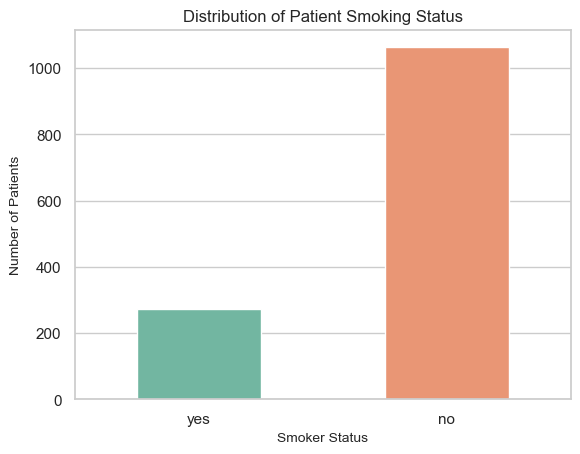

--- EXACT COUNTS ---
smoker
no     1063
yes     274
Name: count, dtype: int64

--- PERCENTAGES ---
smoker
no    79.51
yes   20.49
Name: proportion, dtype: float64


In [15]:
sns.countplot(data=df, x='smoker', hue='smoker', palette='Set2', legend=False,width=0.5)
plt.title('Distribution of Patient Smoking Status', fontsize=12)
plt.xlabel('Smoker Status', fontsize=10)
plt.ylabel('Number of Patients', fontsize=10)
plt.show()

# Print exact counts and percentages
print("--- EXACT COUNTS ---")
print(df['smoker'].value_counts())
print("\n--- PERCENTAGES ---")
print(df['smoker'].value_counts(normalize=True) * 100)

Key Finding (Smoker Distribution):
Non-smokers represent the vast majority of policyholders (~80%, 1,064 patients).
Smokers make up only ~20% of the customer base (273 patients).
This creates a class imbalance in lifestyle risk, making smoking status a high-impact feature for predicting charges.

Children distribution analysis(Univariate)

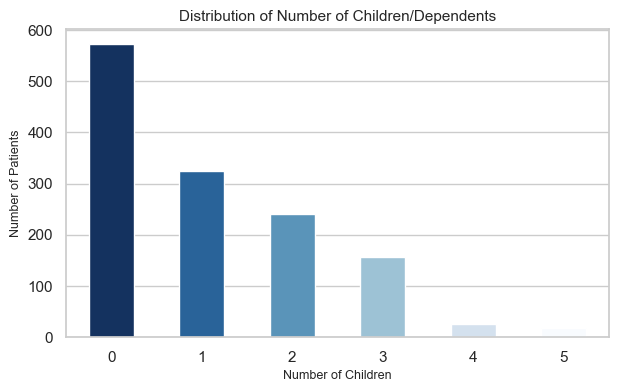

EXACT COUNTS
children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

PERCENTAGES
children
0   42.86
1   24.23
2   17.95
3   11.74
4    1.87
5    1.35
Name: proportion, dtype: float64


In [16]:
plt.figure(figsize=(7, 4))
sns.countplot( data=df,  x='children',  hue='children',  palette='Blues_r', legend=False,  width=0.5)
plt.title('Distribution of Number of Children/Dependents', fontsize=11)
plt.xlabel('Number of Children', fontsize=9)
plt.ylabel('Number of Patients', fontsize=9)
plt.show()

# Print exact counts and percentages
print("EXACT COUNTS")
print(df['children'].value_counts().sort_index())
print("\nPERCENTAGES")
print((df['children'].value_counts(normalize=True).sort_index() * 100).round(2))

Key Finding (Children/Dependents Distribution):
Over 42% of policyholders have no dependents (0 children).
The proportion of customers decreases steadily as the number of children increases.
Families with 4 or 5 children represent a very small fraction (<4%) of the total customer base.

Regional Distribution Analysis using countplot (Univariate)

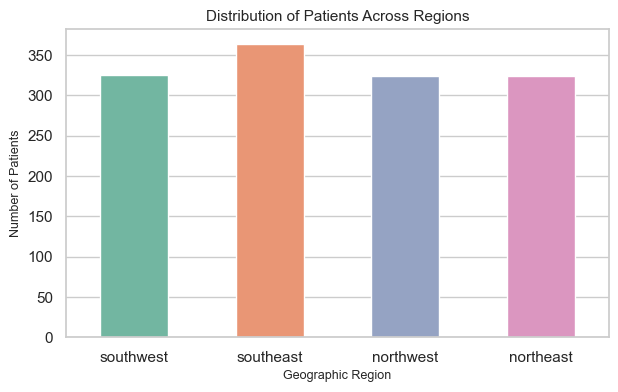

EXACT COUNTS
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

PERCENTAGES
region
southeast   27.23
southwest   24.31
northwest   24.23
northeast   24.23
Name: proportion, dtype: float64


In [17]:
plt.figure(figsize=(7,4))
sns.countplot(data=df,x='region',hue='region',palette='Set2',legend=False,width=0.5)
plt.title('Distribution of Patients Across Regions', fontsize=11)
plt.xlabel('Geographic Region', fontsize=9)
plt.ylabel('Number of Patients', fontsize=9)
plt.show()

print("EXACT COUNTS")
print(df['region'].value_counts())
print("\nPERCENTAGES")
print((df['region'].value_counts(normalize=True) * 100).round(2))

Key Finding (Region Distribution):**
The policyholder population is remarkably evenly spread across the southwest, northwest, and northeast regions (~24.3% each).
The southeast region has the highest concentration of policyholders (~27.2%, 364 patients).
The dataset provides a balanced geographical baseline for regional cost comparisons.

Insurance Charges Distribution Analysis (Univariate Target Analysis)

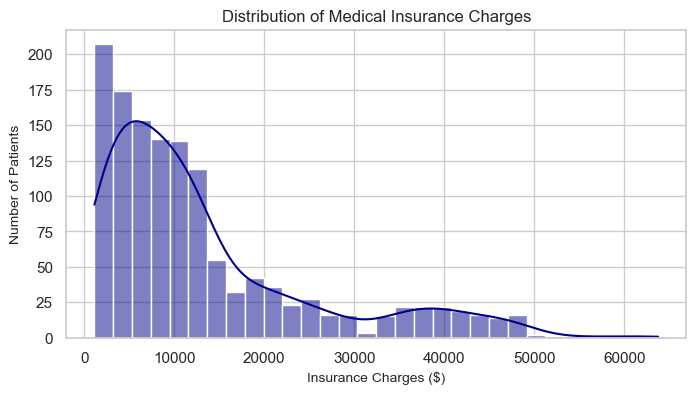

CHARGES SUMMARY STATISTICS
Mean Charges:   $13,279.12
Median Charges: $9,386.16
Min Charges:    $1,121.87
Max Charges:    $63,770.43


In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(df['charges'], kde=True, bins=30, color='darkblue')
plt.title('Distribution of Medical Insurance Charges', fontsize=12)
plt.xlabel('Insurance Charges ($)', fontsize=10)
plt.ylabel('Number of Patients', fontsize=10)
plt.show()

print("CHARGES SUMMARY STATISTICS")
print(f"Mean Charges:   ${df['charges'].mean():,.2f}")
print(f"Median Charges: ${df['charges'].median():,.2f}")
print(f"Min Charges:    ${df['charges'].min():,.2f}")
print(f"Max Charges:    ${df['charges'].max():,.2f}")

Key Findings (Insurance Charges Distribution):
The distribution of `charges` is strongly right-skewed (positively skewed).
The majority of policyholders incur medical charges under $10,000, with a median cost of $9,382.
High-cost outliers (reaching up to $63,770) pull the average mean cost up to $13,270.
Secondary clusters exist near $20,000 and $40,000, indicating distinct sub-populations of high-risk customers.

BIVARIATE ANALYSIS

Bivariate Analysis 1: Smoking Status vs. Insurance Charges

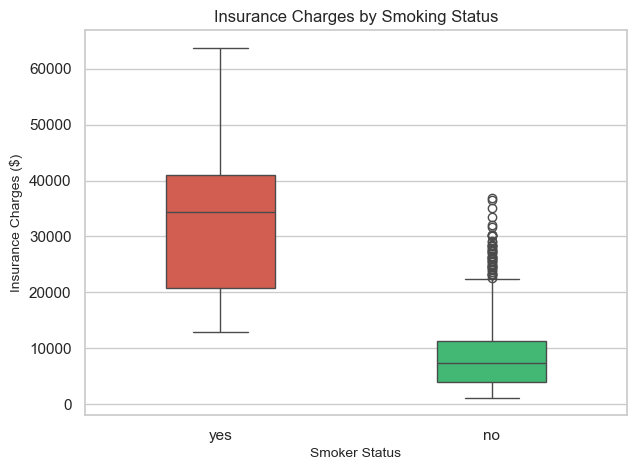

CHARGES SUMMARY BY SMOKER STATUS
          count      mean       std       min       25%       50%       75%  \
smoker                                                                        
no     1,063.00  8,440.66  5,992.97  1,121.87  3,988.88  7,345.73 11,363.02   
yes      274.00 32,050.23 11,541.55 12,829.46 20,826.24 34,456.35 41,019.21   

             max  
smoker            
no     36,910.61  
yes    63,770.43  


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='smoker', y='charges', hue='smoker', palette={'yes': '#e74c3c', 'no': '#2ecc71'}, legend=False, width=0.4)
plt.title('Insurance Charges by Smoking Status', fontsize=12)
plt.xlabel('Smoker Status', fontsize=10)
plt.ylabel('Insurance Charges ($)', fontsize=10)
plt.show()

print("CHARGES SUMMARY BY SMOKER STATUS")
print(df.groupby('smoker')['charges'].describe().round(2))

Key Findings
Primary Cost Driver: Smoking status creates the largest separation in insurance costs across all groups in the dataset.
4x Cost Discrepancy: Smokers incur an average charge of $32,050 compared to $8,434 for non-smokers.
Distinct Group Separation: The median charge for smokers ($34,456) is roughly 5x that of non-smokers ($7,345), with almost no overlap between their core cost ranges.

Bivariate Analysis: BMI vs. Insurance Charges

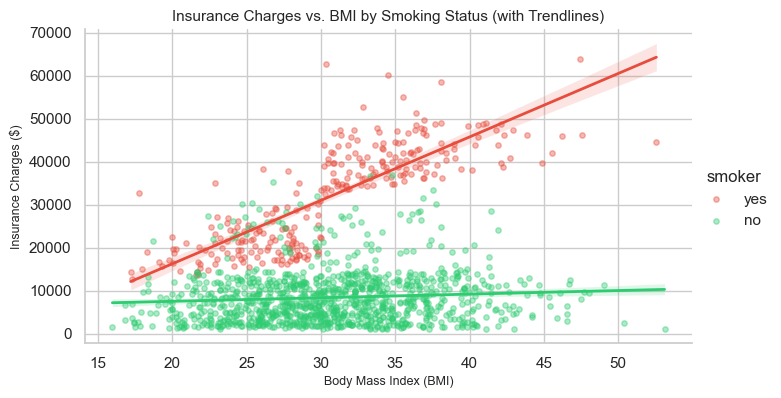

In [20]:
g = sns.lmplot(
    data=df,
    x='bmi',
    y='charges',
    hue='smoker',
    palette={'yes': '#e74c3c', 'no': '#2ecc71'},
    scatter_kws={'s': 15, 'alpha': 0.4}, 
    line_kws={'linewidth': 2},       
    height=4,
    aspect=1.8
)

plt.title('Insurance Charges vs. BMI by Smoking Status (with Trendlines)', fontsize=11)
plt.xlabel('Body Mass Index (BMI)', fontsize=9)
plt.ylabel('Insurance Charges ($)', fontsize=9)

plt.show()

Key Findings:
Flat Trend for Non-Smokers: For non-smokers, charges remain low and relatively flat across all BMI levels, mostly staying under $10,000–$15,000.
Pre-Obesity Elevation: Smokers approaching the obesity threshold (BMI 25–29.9) already face elevated charges ($15,000–$25,000), showing that weight increases baseline risk for smokers early on.
Obesity Surge & Divergence: Crossing the BMI 30 threshold causes smokers' charges to jump sharply above $30,000, creating a steep trendline that widens the cost gap between smokers and non-smokers.

Bivariate Analysis: Age vs. Insurance Charges

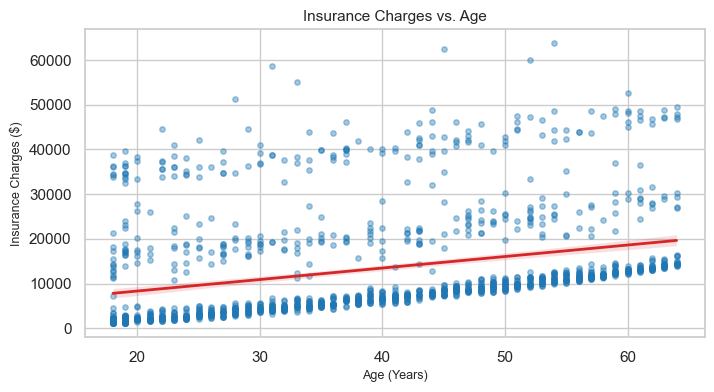

In [21]:
plt.figure(figsize=(8, 4))
sns.regplot(
    data=df,
    x='age',
    y='charges',
    color='#1f77b4',
    scatter_kws={'s': 15, 'alpha': 0.4},  
    line_kws={'color': '#d62728', 'linewidth': 2} 
)
plt.title('Insurance Charges vs. Age', fontsize=11)
plt.xlabel('Age (Years)', fontsize=9)
plt.ylabel('Insurance Charges ($)', fontsize=9)

plt.show()

Key Findings:
Steady Positive Slope: Charges display a clear upward baseline trend as age increases from 18 to 64 years.
Distinct Tiered Banding: Points form three distinct horizontal bands across the age spectrum, reflecting underlying subgroups within each age bracket.
Increasing Baseline Minimum: The minimum cost floor rises predictably with age, moving from $1,100 at age 18 to $11,000+ by age 64.

Bivariate Analysis: Sex vs. Insurance Charges

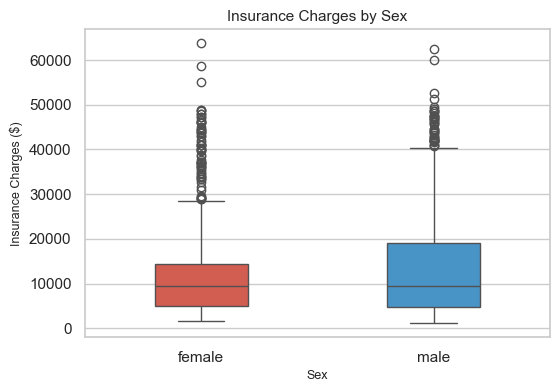

SUMMARY STATISTICS (CHARGES BY SEX)
        count      mean       std      min      25%      50%       75%  \
sex                                                                      
female 662.00 12,569.58 11,128.70 1,607.51 4,885.16 9,412.96 14,454.69   
male   675.00 13,975.00 12,971.96 1,121.87 4,654.02 9,377.90 19,006.69   

             max  
sex               
female 63,770.43  
male   62,592.87  


In [22]:
plt.figure(figsize=(6, 4))

# Boxplot comparing charges by sex
sns.boxplot(
    data=df, 
    x='sex', 
    y='charges', 
    hue='sex', 
    palette={'male': '#3498db', 'female': '#e74c3c'}, 
    legend=False,
    width=0.4
)

plt.title('Insurance Charges by Sex', fontsize=11)
plt.xlabel('Sex', fontsize=9)
plt.ylabel('Insurance Charges ($)', fontsize=9)

plt.show()

# Print summary statistics grouped by sex
print("SUMMARY STATISTICS (CHARGES BY SEX)")
print(df.groupby('sex')['charges'].describe().round(2))

Key Findings
Similar Median Charges: Female ($9,413) and male ($9,348) policyholders show virtually identical median insurance costs.
Slightly Higher Male Average: Males have a slightly higher mean charge ($13,957) compared to females ($12,570), driven by a higher prevalence of high-cost outliers in the upper tail.
Minimal Direct Impact: Gender alone shows no substantial separation in baseline medical costs, making it a low-impact feature for charges on its own.

Bivariate Analysis: Region vs. Insurance Charges

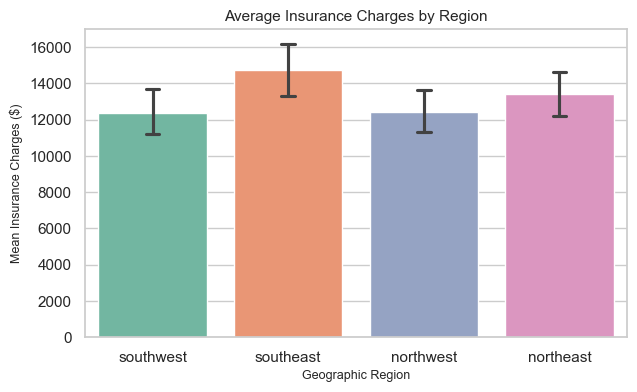

--- SUMMARY STATISTICS (CHARGES BY REGION) ---
           count      mean       std      min      25%       50%       75%  \
region                                                                       
northeast 324.00 13,406.38 11,255.80 1,694.80 5,194.32 10,057.65 16,687.36   
northwest 324.00 12,450.84 11,073.13 1,621.34 4,733.64  8,976.98 14,788.75   
southeast 364.00 14,735.41 13,971.10 1,121.87 4,440.89  9,294.13 19,526.29   
southwest 325.00 12,346.94 11,557.18 1,241.56 4,751.07  8,798.59 13,462.52   

                max  
region               
northeast 58,571.07  
northwest 60,021.40  
southeast 63,770.43  
southwest 52,590.83  


In [23]:
plt.figure(figsize=(7, 4))
sns.barplot(
    data=df, 
    x='region', 
    y='charges', 
    hue='region', 
    palette='Set2', 
    legend=False,
    capsize=0.1
)
plt.title('Average Insurance Charges by Region', fontsize=11)
plt.xlabel('Geographic Region', fontsize=9)
plt.ylabel('Mean Insurance Charges ($)', fontsize=9)
plt.show()

print("--- SUMMARY STATISTICS (CHARGES BY REGION) ---")
print(df.groupby('region')['charges'].describe().round(2))

Key Findings
Highest Average in Southeast: The Southeast region has the highest average medical cost (14,735), standing noticeably above the other three regions.
Comparable Western & Northeastern Averages: The Northeast ($13,406), Northwest (12,417), and Southwest (12,347) show relatively similar lower average costs.
Overall Low Regional Variation: Aside from the Southeast's higher mean, geographic location exerts a far weaker effect on overall charges than individual health metrics like smoking or age.

Multivariate Analysis

Feature Correlation Matrix (Heatmap)

<module 'matplotlib.pyplot' from 'C:\\ProgramData\\anaconda3\\Lib\\site-packages\\matplotlib\\pyplot.py'>

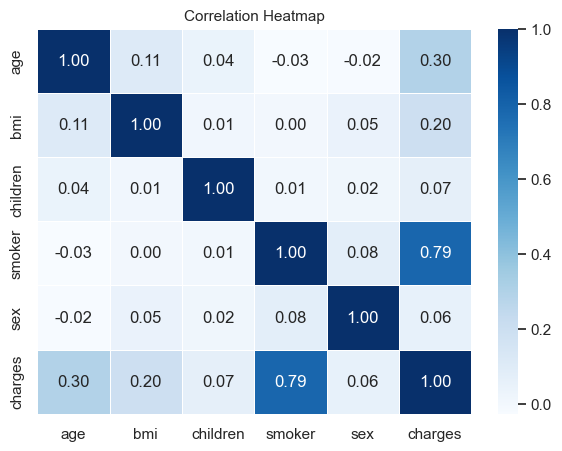

In [24]:

df_encoded = df.copy()
df_encoded['smoker'] = df_encoded['smoker'].map({'yes': 1, 'no': 0})
df_encoded['sex'] = df_encoded['sex'].map({'male': 1, 'female': 0})
num_cols = ['age', 'bmi', 'children', 'smoker', 'sex', 'charges']
corr = df_encoded[num_cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap', fontsize=11)
plt

Key Findings:
Strongest Predictor: smoker shows the highest positive correlation with charges (0.79).
Secondary Linear Features: age (0.30) and bmi (0.20) demonstrate moderate positive correlations with total charges.
Low Multicollinearity: Predictor features show weak inter-correlation (e.g., age vs. bmi 0.11), indicating independent signal contributions for modeling.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [26]:
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first = True,dtype = int) 
print(df_encoded)

      age   bmi  children   charges  sex_male  smoker_yes  region_northwest  \
0      19 27.90         0 16,884.92         0           1                 0   
1      18 33.77         1  1,725.55         1           0                 0   
2      28 33.00         3  4,449.46         1           0                 0   
3      33 22.70         0 21,984.47         1           0                 1   
4      32 28.88         0  3,866.86         1           0                 1   
...   ...   ...       ...       ...       ...         ...               ...   
1332   50 30.97         3 10,600.55         1           0                 1   
1333   18 31.92         0  2,205.98         0           0                 0   
1334   18 36.85         0  1,629.83         0           0                 0   
1335   21 25.80         0  2,007.94         0           0                 0   
1336   61 29.07         0 29,141.36         0           1                 1   

      region_southeast  region_southwest  
0       

In [27]:
x = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']
print(x)
print(y)

      age   bmi  children  sex_male  smoker_yes  region_northwest  \
0      19 27.90         0         0           1                 0   
1      18 33.77         1         1           0                 0   
2      28 33.00         3         1           0                 0   
3      33 22.70         0         1           0                 1   
4      32 28.88         0         1           0                 1   
...   ...   ...       ...       ...         ...               ...   
1332   50 30.97         3         1           0                 1   
1333   18 31.92         0         0           0                 0   
1334   18 36.85         0         0           0                 0   
1335   21 25.80         0         0           0                 0   
1336   61 29.07         0         0           1                 1   

      region_southeast  region_southwest  
0                    0                 1  
1                    1                 0  
2                    1                 0  

In [28]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [37]:
model = LinearRegression()
model.fit(x_train, y_train)
print("Model has been successfully trained.")

Model has been successfully trained.


In [30]:
y_pred = model.predict(x_test)
print(y_pred)

[ 8.14369388e+03  5.73711568e+03  1.43693149e+04  3.17455136e+04
  8.96238666e+03  1.31497224e+04  3.04467607e+04  1.45328881e+03
  1.06330184e+04  1.13189438e+04  1.03778536e+04  3.31184377e+04
  3.10772527e+04  1.74119253e+04  1.08016743e+04  9.52889964e+03
  4.16103784e+03  3.17315373e+04  3.21938875e+03  5.22992460e+03
  3.54979004e+03  3.02837740e+04  1.48989509e+04  3.04569093e+04
  3.11077668e+04  5.51196081e+03  3.55030401e+04  3.65704810e+04
  1.14123133e+04  1.42056990e+04  6.50234029e+03  1.27246945e+04
  3.99806590e+02  1.20883980e+04  3.96592069e+04  1.23395540e+04
  4.74412279e+03  3.91903157e+03  3.08606789e+04  8.95870663e+03
  7.05389441e+03  3.01125636e+04  3.47804324e+04  1.22916189e+04
  7.35739310e+03  3.42060530e+03  6.21243471e+03  8.98345200e+03
  4.26401828e+03  9.01992870e+03  6.60149578e+03  1.20802337e+04
  3.12447687e+04  3.55341947e+03  1.10470477e+04  9.73512492e+03
  1.08383403e+04  2.42942719e+03  3.11621909e+04  9.40578078e+03
  1.55793421e+04  8.19158

In [31]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Average Prediction Error (RMSE): ${rmse:,.2f}")
print(f"Model Accuracy Score (R2): {r2:.4f}")

Average Prediction Error (RMSE): $5,956.34
Model Accuracy Score (R2): 0.8069


In [32]:
coefficients = pd.DataFrame({
    'Feature': x.columns,
    'Impact on Charge ($)': model.coef_
}).sort_values(by='Impact on Charge ($)', ascending=False)

print(coefficients)

            Feature  Impact on Charge ($)
4        smoker_yes             23,077.76
2          children                533.01
1               bmi                318.70
0               age                248.21
3          sex_male               -101.54
5  region_northwest               -391.76
7  region_southwest               -659.14
6  region_southeast               -838.92


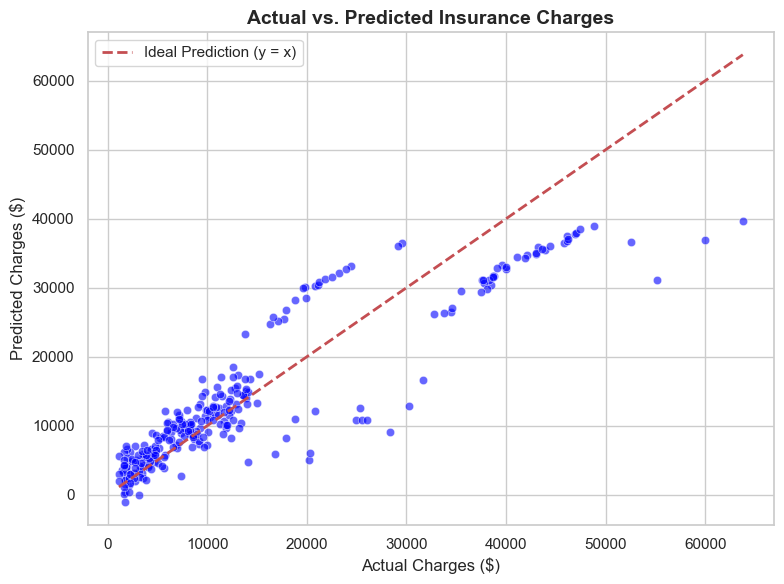

In [33]:
import statsmodels.api as sm

# Calculate residual errors on the test set
residuals = y_test - y_pred

# Set general plot style for clean visuals
sns.set_theme(style="whitegrid")

# ----------------------------------------------------
# Visual 1: Actual vs. Predicted Charges
# ----------------------------------------------------
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='blue')

# Red dashed line representing perfect 1-to-1 prediction (y = x)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Prediction (y = x)')

plt.title('Actual vs. Predicted Insurance Charges', fontsize=14, fontweight='bold')
plt.xlabel('Actual Charges ($)', fontsize=12)
plt.ylabel('Predicted Charges ($)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

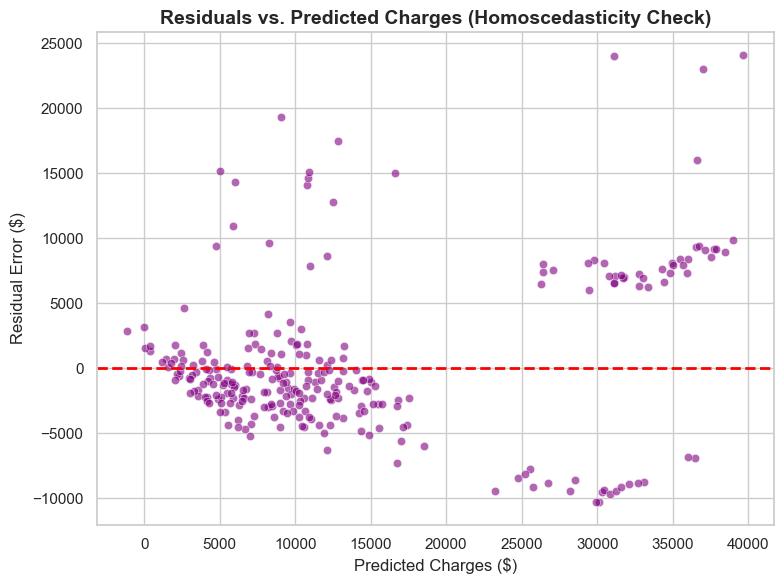

In [34]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, color='purple')

# Zero reference line
plt.axhline(0, color='red', linestyle='--', lw=2)

plt.title('Residuals vs. Predicted Charges (Homoscedasticity Check)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Charges ($)', fontsize=12)
plt.ylabel('Residual Error ($)', fontsize=12)
plt.tight_layout()
plt.show()

In [35]:
new_patient = pd.DataFrame([{
    'age': 35,
    'bmi': 28.5,
    'children': 2,
    'sex_male': 1,          # 1 = male, 0 = female
    'smoker_yes': 1,        # 1 = yes, 0 = no
    'region_northwest': 0,
    'region_southeast': 1,  # 1 = southeast,if the 3 regions are 0 then region is northeast
    'region_southwest': 0
}])
y_pred = model.predict(new_patient)
print(f"Predicted Charge: ${y_pred[0]:,.2f}")

Predicted Charge: $29,881.04
